In [51]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Cargar el archivo CSV subido
df = pd.read_csv("housing.csv")
#del df['ocean_proximity']
df = pd.get_dummies(df)
df = df.fillna(df.mean())

X = df.drop(['median_house_value'], axis=1)
y = df['median_house_value']

nombres_limpios = [col.replace('<', '').replace('>', '').replace('[', '').replace(']', '') for col in X.columns]
X.columns = nombres_limpios


### Escalar datos y hacer PCA

In [52]:
pipeline=Pipeline([
    ('scaler',StandardScaler()),
    ('pca',PCA())
])

In [53]:
pipeline.fit(X)

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA())])

### Varianza explicada

Si la primera componente principal se obtiene con el eigenvalor que máximiza la varianza.

La varianza explicada por cada componente principal 

$$varianza_i = \frac{Eigenvalor_i}{\Sigma{Eigenvalores}}$$


In [54]:
principal_components=pipeline.named_steps['pca']

In [55]:
principal_components.explained_variance_

array([3.92024762, 2.56614968, 1.64809821, 1.25638398, 1.07410183,
       0.99678352, 0.71263886, 0.573732  , 0.14651031, 0.06043233,
       0.02657166, 0.01897988, 0.        ])

In [56]:
principal_components.explained_variance_ratio_

array([0.3015429 , 0.19738657, 0.12677064, 0.09664024, 0.08261921,
       0.07667194, 0.05481572, 0.04413109, 0.01126948, 0.00464842,
       0.00204387, 0.00145992, 0.        ])

### Entendiendo primera componente

In [57]:
pc1=pd.DataFrame({
    'names':X.keys(),
    'componente1':principal_components.components_[0]
})
pc1

,names,componente1
0,longitude,0.101538
1,latitude,-0.099569
2,housing_median_age,-0.220563
3,total_rooms,0.478316
4,total_bedrooms,0.484269
5,population,0.469222
6,households,0.486598
7,median_income,0.048330
8,ocean_proximity_1H OCEAN,0.057847
9,ocean_proximity_INLAND,-0.012784


### Entendiendo segunda componente

In [58]:

X_pca=principal_components.fit_transform(X)
X_pca=pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(X_pca.shape[1])])
X_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-2130.424338,-253.083865,-65.945026,6.311785,9.099242,2.665215,4.390168,0.444167,-0.356480,0.613601,-0.209276,-0.000178,6.150636e-14
1,4529.085931,-1035.137595,-35.660184,131.193022,0.649646,2.398444,1.983581,0.005005,-0.299904,0.656461,-0.232345,0.000665,6.222800e-14
2,-1522.716704,-352.662897,-109.586767,4.712494,21.568635,2.593431,3.006068,0.307668,-0.314851,0.568102,-0.180164,-0.000588,2.192690e-14
3,-1653.597500,-204.955647,-32.550496,3.711245,20.802263,2.816134,1.944722,0.111889,-0.309778,0.580434,-0.170689,-0.000738,6.883383e-15
4,-1326.256265,-350.151377,-28.577787,9.339638,21.545809,2.882624,-0.046882,-0.286029,-0.281939,0.596868,-0.163944,-0.000994,-2.109424e-14
...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-1150.071776,-106.838823,27.508408,-8.902986,-5.521702,4.022989,-2.056181,0.945585,0.437786,-0.227783,-0.476196,0.001499,3.971823e-13
20636,-2275.932968,-141.388993,-36.289801,-20.091633,-14.105630,4.068800,-1.175775,0.882667,0.374415,-0.182913,-0.435565,0.001518,3.784195e-13
20637,-529.914794,-210.264230,55.197304,-1.624294,-12.437949,4.099533,-2.037700,0.754155,0.387111,-0.185988,-0.399500,0.001454,3.496092e-13
20638,-1013.162812,-282.615933,55.630074,-9.452284,-12.097365,4.088994,-1.845340,0.717255,0.370171,-0.185723,-0.348695,0.001253,3.178013e-13


### Obtener las componentes principales

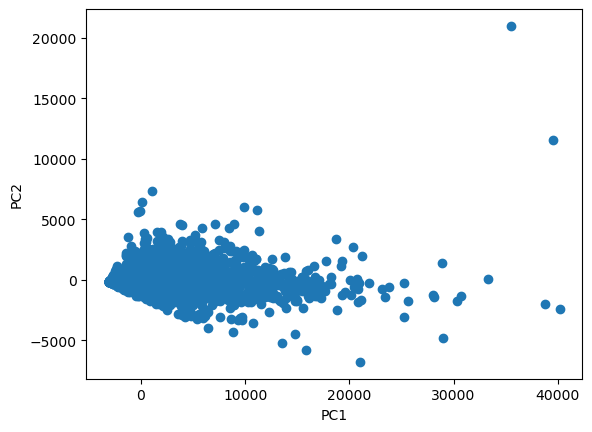

In [59]:
plt.scatter(X_pca['PC1'],X_pca['PC2'])
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend
plt.show()

### Visualizar componentes principales

## Modelos de datos

### Primero con todos los features

In [60]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

model=XGBRegressor()
X_pc12=X_pca[['PC1','PC2','PC3','PC4']]

model.fit(X_pc12,y)
predicciones=model.predict(X_pc12)
r2_score(y_pred=predicciones,y_true=y)
              

0.6153793385503615

### Ahora con las componentes principales

### Ahora solo con las primeras 3 componentes

### Conclusión: a medida que agregamos más componentes aumenta el poder predictivo pero se pierde el objetivo inicial que es tener menos dimensiones

### Clustering + PCA

In [61]:
from sklearn.cluster import Kmeans

ImportError: cannot import name 'Kmeans' from 'sklearn.cluster' (/opt/anaconda3/lib/python3.13/site-packages/sklearn/cluster/__init__.py)